In [1]:
# Setup
import re
import warnings
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde

from config import (
    DATA_DIR,
    FIGURES_DIR,
    DEFAULT_METADATA_PATH,
    DEFAULT_TAX_PATH,
    DEFAULT_PATH_PATH,
    PATHWAY_SCALE,
    UNWANTED_PATHWAY_COLS,
)
from common import read_csv_with_run

warnings.filterwarnings("ignore")

DA_DIR = DATA_DIR / "diff_abundance"
FIGURE_DIR = FIGURES_DIR / "Fig_3_DA"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TOP = 5
SIG = 0.05
PSEUDOCOUNT = 1e-6
DPI = 300

N_VOL_DISEASE = 20
N_VOL_HEALTHY = 5
N_VOL_PATH = 6

PALETTE = {
    "Healthy": "#7DAF86",
    "Periodontitis (K05)": "#7B80C0",
    "Caries (K02)": "#C9A86C",
}
C_H = PALETTE["Healthy"]
C_NS = "#CECECE"
DIS_COL = {
    "K05": PALETTE["Periodontitis (K05)"],
    "K02": PALETTE["Caries (K02)"],
}
BG_TAX = "#F4F4FA"
BG_PATH = "#FAF9F3"

SCALE = 1.0
_BASE_FS = {
    "suptitle": 16,
    "row_title": 15,
    "col_title": 14,
    "axis_label": 12,
    "tick": 8.5,
    "ytick": 12,
    "small": 7.5,
    "annot": 9,
    "legend": 10,
    "star": 7.5,
}
FS = {k: round(v * SCALE, 2) for k, v in _BASE_FS.items()}

VOLCANO_TAXA_LABELS = {
    "K05": {
        "disease": [
            "Tannerella_forsythia",
            "Porphyromonas_gingivalis",
            "Treponema_denticola",
            "Filifactor_alocis",
            "Peptostreptococcus_stomatis",
            "Mogibacterium_timidum",
            "GGB10852_SGB17523",
            "Prevotella_koreensis",
        ],
    },
    "K02": {
        "disease": [
            "Streptococcus_mutans",
            "Streptococcus_sobrinus",
            "Lactobacillus_fermentum",
            "Scardovia_wiggsiae",
            "Prevotella_denticola",
            "Veillonella_parvula",
            "GGB1202_SGB1566",
            "Prevotella_veroralis",
            "Propionibacterium_acidifaciens",
            "Dialister_invisus",
            "Olsenella_profusa",
        ],
    },
}

# Load metadata and abundance tables.
meta = read_csv_with_run(DEFAULT_METADATA_PATH)
run_col = "run"

H_COL = "healthy"
K05_COL = "K05_gingivitis_periodontitis"
K02_COL = "K02_caries"
DIS_COL_MAP = {"K05": K05_COL, "K02": K02_COL}


def load_abundance_table(path: str | Path) -> pd.DataFrame:
    df = read_csv_with_run(path).set_index("run")
    df.index = df.index.astype(str)
    return df


def metaphlan_strip(name: str) -> str:
    name = str(name)
    if "|" in name:
        name = name.split("|")[-1]
    if len(name) > 3 and name[1:3] == "__":
        name = name[3:]
    return name.strip().replace(" ", "_")


tax_df = load_abundance_table(DEFAULT_TAX_PATH)
path_df = load_abundance_table(DEFAULT_PATH_PATH)

tax_df.columns = [metaphlan_strip(c) for c in tax_df.columns]
path_df.columns = [metaphlan_strip(c) for c in path_df.columns]
path_df = path_df.drop(columns=[c for c in UNWANTED_PATHWAY_COLS if c in path_df.columns])
path_df = path_df / PATHWAY_SCALE

print(f"tax  {tax_df.shape}   cols[:3]={list(tax_df.columns[:3])}")
print(f"path {path_df.shape}  cols[:3]={list(path_df.columns[:3])}")

# Normalized lookup for MaAsLin2 feature names.
def _norm(s: str) -> str:
    return re.sub(r"[^a-z0-9]", "_", str(s).lower()).strip("_")


tax_lkp = {_norm(c): c for c in tax_df.columns}
path_lkp = {_norm(c): c for c in path_df.columns}


def find_col(feat: str, lkp: dict[str, str]) -> str | None:
    return lkp.get(_norm(feat))


# Load MaAsLin2 results and per-bioproject p-values.
maaslin, bpdata = {}, {}
for dis in ["K05", "K02"]:
    maaslin[dis], bpdata[dis] = {}, {}
    for sp in ["TAX", "PATH"]:
        maaslin[dis][sp] = pd.read_csv(
            DA_DIR / "maaslin2_output" / dis / sp / "all_results.tsv",
            sep="\t",
        )
        bpdata[dis][sp] = pd.read_csv(
            DA_DIR / "by_bioproject" / f"{dis}_{sp}_all_features_wide.csv",
        )

avail = set(tax_df.index)


def get_groups(dis_code: str) -> tuple[np.ndarray, np.ndarray]:
    disease_col = DIS_COL_MAP[dis_code]
    h_idx = np.array([r for r in meta.loc[meta[H_COL] == 1, run_col].values if r in avail])
    d_idx = np.array([r for r in meta.loc[meta[disease_col] == 1, run_col].values if r in avail])
    print(f"  [{dis_code}] healthy={len(h_idx)} disease={len(d_idx)}")
    return h_idx, d_idx


# Figure-specific formatters and helpers.
def fmt_taxon(raw: str) -> str:
    """Tannerella_forsythia -> T. forsythia"""
    name = str(raw)
    if len(name) > 3 and name[1:3] == "__":
        name = name[3:]
    name = name.replace("_", " ").strip()
    parts = name.split()
    if len(parts) >= 2:
        return f"{parts[0][0]}. {' '.join(parts[1:])}"
    return name


def fmt_pathway(raw: str) -> str:
    """Return the pathway ID before the first '..' and replace dots with hyphens."""
    name = str(raw)
    if len(name) > 3 and name[1:3] == "__":
        name = name[3:]
    code = name.split("..")[0]
    return code.replace(".", "-")


def fmt_left_label(raw: str, is_taxon: bool, maxlen: int = 22) -> str:
    label = fmt_taxon(raw) if is_taxon else fmt_pathway(raw)
    return (label[: maxlen - 3] + "...") if len(label) > maxlen else label


def get_ab(feat: str, ab_df: pd.DataFrame, lkp: dict[str, str], h_idx: np.ndarray, d_idx: np.ndarray):
    col = find_col(feat, lkp)
    if col is None:
        return np.array([]), np.array([])
    h = ab_df.loc[ab_df.index.isin(h_idx), col].values.astype(float)
    d = ab_df.loc[ab_df.index.isin(d_idx), col].values.astype(float)
    h = np.log10(h[np.isfinite(h) & (h >= 0)] + PSEUDOCOUNT)
    d = np.log10(d[np.isfinite(d) & (d >= 0)] + PSEUDOCOUNT)
    return h, d


def half_violin(ax, vals, yc, side, color, w=0.40):
    vals = np.asarray(vals, float)
    vals = vals[np.isfinite(vals)]
    if len(vals) < 5 or (vals.max() - vals.min()) < 1e-8:
        return
    try:
        kde = gaussian_kde(vals, bw_method=0.4)
        xg = np.linspace(vals.min(), vals.max(), 200)
        den = kde(xg)
        den = den / den.max() * w
        if side == "up":
            ax.fill_between(xg, yc, yc + den, color=color, alpha=0.30, lw=0, zorder=3)
            ax.plot(xg, yc + den, color=color, lw=1.2, alpha=0.90, zorder=4)
        else:
            ax.fill_between(xg, yc - den, yc, color=color, alpha=0.30, lw=0, zorder=3)
            ax.plot(xg, yc - den, color=color, lw=1.2, alpha=0.90, zorder=4)
        med = np.median(vals)
        ax.vlines(med, yc - w * 0.22, yc + w * 0.22, color="white", lw=2.0, zorder=5)
        ax.vlines(med, yc - w * 0.22, yc + w * 0.22, color=color, lw=0.9, alpha=0.7, zorder=6)
    except Exception as e:
        print(f"  [violin error] {e}")


def get_bp_pvals(dis: str, sp: str, features: list[str]) -> pd.DataFrame:
    df = bpdata[dis][sp].drop_duplicates(subset="feature")
    pcols = [c for c in df.columns if c.endswith("__bp_pval")]
    bps = [c.replace("__bp_pval", "") for c in pcols]
    idx = df.set_index("feature")[pcols]
    idx.columns = bps
    res = pd.DataFrame(index=features, columns=bps, dtype=float)
    for feature in features:
        if feature in idx.index:
            res.loc[feature] = idx.loc[feature].values
    return res


def p2star(p) -> str:
    try:
        p = float(p)
    except Exception:
        return ""
    if np.isnan(p) or p >= SIG:
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    return "*"


tax  (514, 719)   cols[:3]=['GGB4964_SGB6927', 'Prevotella_pleuritidis', 'TM7_phylum_sp_oral_taxon_348']
path (514, 522)  cols[:3]=['12DICHLORETHDEG-PWY:_1,2-dichloroethane_degradation', '1CMET2-PWY:_folate_transformations_III_(E._coli)', '3-HYDROXYPHENYLACETATE-DEGRADATION-PWY:_4-hydroxyphenylacetate_degradation']


In [2]:
# Draw one row
def draw_row(fig, slot, dis_code, title, show_col_titles=True, show_xlabels=True):
    C_D = DIS_COL[dis_code]
    n   = 2 * TOP

    inner = gridspec.GridSpecFromSubplotSpec(
        1, 5, subplot_spec=slot,
        width_ratios=[4.0, 3.4, 1.7, 1.7, 4.2], wspace=0.10)

    ax_st = fig.add_subplot(inner[0])
    vi_gs = gridspec.GridSpecFromSubplotSpec(
        2, 1, subplot_spec=inner[1],
        height_ratios=[TOP, TOP], hspace=0.0)
    ax_vi_t = fig.add_subplot(vi_gs[0])
    ax_vi_p = fig.add_subplot(vi_gs[1])
    ax_qv   = fig.add_subplot(inner[2], sharey=ax_st)
    ax_cf   = fig.add_subplot(inner[3], sharey=ax_st)
    ax_vol  = fig.add_subplot(inner[4])

    # top features
    top_tax  = maaslin[dis_code]["TAX"].sort_values("qval").head(TOP).reset_index(drop=True)
    top_path = maaslin[dis_code]["PATH"].sort_values("qval").head(TOP).reset_index(drop=True)
    feats    = top_tax["feature"].tolist() + top_path["feature"].tolist()
    y_of     = {f: n - 1 - i for i, f in enumerate(feats)}
    info     = pd.concat([top_tax, top_path], ignore_index=True)

    # section backgrounds
    for ax in [ax_st, ax_qv, ax_cf]:
        ax.axhspan(TOP - 0.5, n - 0.5, color=BG_TAX,  zorder=0)
        ax.axhspan(-0.5,      TOP - 0.5, color=BG_PATH, zorder=0)
    ax_vi_t.set_facecolor(BG_TAX)
    ax_vi_p.set_facecolor(BG_PATH)

    # Stars heatmap
    bp_tax  = get_bp_pvals(dis_code, "TAX",  top_tax["feature"].tolist())
    bp_path = get_bp_pvals(dis_code, "PATH", top_path["feature"].tolist())
    all_bps = list(dict.fromkeys(bp_tax.columns.tolist() + bp_path.columns.tolist()))
    bp_comb = pd.DataFrame(index=feats, columns=all_bps, dtype=float)
    for f in top_tax["feature"]:
        for bp in bp_tax.columns: bp_comb.loc[f, bp] = bp_tax.loc[f, bp]
    for f in top_path["feature"]:
        for bp in bp_path.columns: bp_comb.loc[f, bp] = bp_path.loc[f, bp]
    bp_short = [b.replace("PRJNA", "").replace("PRJEB", "E") for b in all_bps]

    for bi, bp in enumerate(all_bps):
        for fi, feat in enumerate(feats):
            y   = y_of[feat]
            p   = bp_comb.loc[feat, bp]
            c   = info.iloc[fi]["coef"]
            sig = not (pd.isna(p) or float(p) >= SIG)
            bg  = (C_D if c > 0 else C_H) if sig else C_NS
            ax_st.scatter(bi, y, s=270, c=bg, marker="s",
                          linewidths=0.4, edgecolors="#FFFFFF", alpha=0.92, zorder=2)
            star = p2star(p)
            if star:
                ax_st.text(bi, y, star, ha="center", va="center",
                           fontsize=FS["star"], color="white", fontweight="bold", zorder=3)

    # y-axis labels: taxa abbreviated, pathways as IDs
    ys_ord = sorted(y_of.items(), key=lambda kv: kv[1])
    tick_labels = []
    for feat, yp in ys_ord:
        is_taxon = (yp >= TOP)
        tick_labels.append(fmt_left_label(feat, is_taxon))
    ax_st.set_yticks([kv[1] for kv in ys_ord])
    ax_st.set_yticklabels(tick_labels, fontsize=FS["ytick"])
    for lbl, (_, yp) in zip(ax_st.get_yticklabels(), ys_ord):
        if yp >= TOP: lbl.set_fontstyle("italic")

    ax_st.set_xlim(-0.6, len(all_bps) - 0.4)
    ax_st.set_ylim(-0.6, n - 0.4)
    ax_st.set_xticks(range(len(all_bps)))
    ax_st.set_xticklabels(bp_short, rotation=-35, ha="right", fontsize=FS["tick"])
    ax_st.xaxis.tick_top()
    ax_st.axhline(TOP - 0.5, color="#999", lw=1.2, ls="--", zorder=4)
    ax_st.tick_params(length=0, pad=3)
    for s in ax_st.spines.values(): s.set_visible(False)

    if show_col_titles:
        ax_st.set_title(title, fontsize=FS["row_title"], fontweight="bold",
                        loc="left", pad=28, color=C_D)
    else:
        ax_st.text(-0.01, -0.01, title, transform=ax_st.transAxes,
                   fontsize=FS["row_title"], fontweight="bold", color=C_D,
                   va="top", ha="left")

    # Split violins
    h_idx, d_idx = get_groups(dis_code)
    ax_vi_t.set_ylim(TOP - 0.5, n - 0.5)
    ax_vi_p.set_ylim(-0.5, TOP - 0.5)
    for fi, feat in enumerate(feats):
        y = y_of[feat]
        if fi < TOP: ax, lkp, ab = ax_vi_t, tax_lkp, tax_df
        else:        ax, lkp, ab = ax_vi_p, path_lkp, path_df
        hv, dv = get_ab(feat, ab, lkp, h_idx, d_idx)
        half_violin(ax, hv, y, "down", C_H)
        half_violin(ax, dv, y, "up",   C_D)

    ax_vi_t.tick_params(axis="x", labelsize=FS["tick"])
    ax_vi_t.tick_params(axis="y", length=0)
    plt.setp(ax_vi_t.get_yticklabels(), visible=False)
    ax_vi_t.spines["right"].set_visible(False)
    ax_vi_t.spines["top"].set_visible(False)
    ax_vi_t.spines["bottom"].set_color("#AAAAAA")
    ax_vi_t.spines["bottom"].set_linewidth(0.6)
    ax_vi_t.spines["bottom"].set_linestyle("--")
    if show_col_titles:
        ax_vi_t.set_title("Abundance (log10)", fontsize=FS["col_title"], pad=28, color="#333")

    ax_vi_p.tick_params(axis="x", labelsize=FS["tick"])
    ax_vi_p.tick_params(axis="y", length=0)
    plt.setp(ax_vi_p.get_yticklabels(), visible=False)
    ax_vi_p.spines["right"].set_visible(False)
    ax_vi_p.spines["top"].set_visible(False)
    ax_vi_p.spines["bottom"].set_visible(True)
    if show_xlabels:
        ax_vi_p.set_xlabel("log10(abund. + eps)", fontsize=FS["axis_label"])
    ax_vi_t.text(0.99, 0.97, "taxa",     transform=ax_vi_t.transAxes,
                 ha="right", va="top",    fontsize=FS["small"], color="#888", fontstyle="italic")
    ax_vi_p.text(0.99, 0.03, "pathways", transform=ax_vi_p.transAxes,
                 ha="right", va="bottom", fontsize=FS["small"], color="#888", fontstyle="italic")

    # -log10(q) bars
    for fi in range(n):
        row = info.iloc[fi]; y = y_of[feats[fi]]
        ax_qv.barh(y, -np.log10(row["qval"] + 1e-300), height=0.65,
                   color=(C_D if row["coef"] > 0 else C_H), alpha=0.85)
    ax_qv.axvline(-np.log10(SIG), color="#777", lw=0.8, ls="--")
    ax_qv.axhline(TOP - 0.5, color="#999", lw=1.2, ls="--", zorder=4)
    ax_qv.tick_params(axis="x", labelsize=FS["tick"])
    ax_qv.tick_params(axis="y", length=0)
    plt.setp(ax_qv.get_yticklabels(), visible=False)
    for s in ["top", "right"]: ax_qv.spines[s].set_visible(False)
    if show_col_titles: ax_qv.set_title("Significance", fontsize=FS["col_title"], pad=28, color="#333")
    if show_xlabels:    ax_qv.set_xlabel("-log(q)", fontsize=FS["axis_label"])

    # Coef bars
    for fi in range(n):
        row = info.iloc[fi]; y = y_of[feats[fi]]
        ax_cf.barh(y, row["coef"], height=0.65,
                   color=(C_D if row["coef"] > 0 else C_H), alpha=0.85)
    ax_cf.axvline(0, color="#666", lw=0.8)
    ax_cf.axhline(TOP - 0.5, color="#999", lw=1.2, ls="--", zorder=4)
    ax_cf.tick_params(axis="x", labelsize=FS["tick"])
    ax_cf.tick_params(axis="y", length=0)
    plt.setp(ax_cf.get_yticklabels(), visible=False)
    for s in ["top", "right"]: ax_cf.spines[s].set_visible(False)
    if show_col_titles: ax_cf.set_title("Effect size", fontsize=FS["col_title"], pad=28, color="#333")
    if show_xlabels:    ax_cf.set_xlabel("Coef (MaAsLin2)", fontsize=FS["axis_label"])

    # Volcano
    ax_vol.margins(x=0.20, y=0.08)

    for sp_lbl, mk, sz, al in [("TAX", "o", 22, 0.80), ("PATH", "D", 13, 0.65)]:
        dfv        = maaslin[dis_code][sp_lbl].copy()
        dfv["nlq"] = -np.log10(dfv["qval"].clip(1e-300))
        ns  = dfv[dfv["qval"] >= SIG]
        up  = dfv[(dfv["qval"] < SIG) & (dfv["coef"] > 0)]
        dn  = dfv[(dfv["qval"] < SIG) & (dfv["coef"] < 0)]
        kw  = dict(marker=mk, lw=0, zorder=2 if sp_lbl == "TAX" else 1)
        ax_vol.scatter(ns["coef"], ns["nlq"], c=C_NS, s=sz, alpha=0.25, **kw)
        ax_vol.scatter(up["coef"], up["nlq"], c=C_D,  s=sz, alpha=al,  **kw)
        ax_vol.scatter(dn["coef"], dn["nlq"], c=C_H,  s=sz, alpha=al,  **kw)

    # Volcano annotations
    # Build label list: (xpt, ypt, label_str, color, fontstyle, x_offset_pt, y_offset_pt)
    #  Edit x_offset_pt / y_offset_pt below to reposition individual labels.
    # Positive x_offset = shift right, negative = shift left (in points).
    df_tax  = maaslin[dis_code]["TAX"].copy()
    df_path = maaslin[dis_code]["PATH"].copy()
    df_tax["nlq"]  = -np.log10(df_tax["qval"].clip(1e-300))
    df_path["nlq"] = -np.log10(df_path["qval"].clip(1e-300))

    annots = []

    # --- disease-side taxa: curated list, filtered to significant rows ---
    curated = VOLCANO_TAXA_LABELS[dis_code]["disease"]
    found_d = 0
    for name in curated:
        row = df_tax[df_tax["feature"].apply(lambda f: _norm(f) == _norm(name))]
        if not row.empty and row.iloc[0]["qval"] < SIG and row.iloc[0]["coef"] > 0:
            r = row.iloc[0]
            annots.append((r["coef"], r["nlq"], fmt_taxon(r["feature"]),
                           C_D, "italic", 10, 3))
            found_d += 1
        if found_d >= N_VOL_DISEASE:
            break

    # --- healthy-side taxa: top N by significance (lowest q, coef < 0) ---
    healthy_rows = (df_tax[(df_tax["qval"] < SIG) & (df_tax["coef"] < 0)]
                    .sort_values("qval").head(N_VOL_HEALTHY))
    for _, r in healthy_rows.iterrows():
        annots.append((r["coef"], r["nlq"], fmt_taxon(r["feature"]),
                       C_H, "italic", -10, 3))

    # --- single most-significant pathway (just to locate it on the plot) ---
    sig_paths = df_path[df_path["qval"] < SIG].sort_values("qval")
    if not sig_paths.empty and N_VOL_PATH > 0:
        r = sig_paths.iloc[0]
        col = C_D if r["coef"] > 0 else C_H
        dx  = 10 if r["coef"] > 0 else -10
        annots.append((r["coef"], r["nlq"], fmt_pathway(r["feature"]),
                       col, "normal", dx, 3))

    # Draw annotations - each has explicit (dx, dy) offset in points for easy repositioning
    texts = []
    for xpt, ypt, label, col, fstyle, dx, dy in annots:
        ha = "left" if dx > 0 else "right"
        ann = ax_vol.annotate(
            label,
            xy=(xpt, ypt),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=FS["annot"],
            color=col,
            fontstyle=fstyle,
            fontweight="semibold",
            ha=ha, va="center",
            clip_on=False,
            zorder=10,
            arrowprops=dict(arrowstyle="-", color="#CCCCCC", lw=0.7,
                            shrinkA=2, shrinkB=2),
        )
        texts.append(ann)

    # axes chrome
    ax_vol.axhline(-np.log10(SIG), color="#888", lw=0.8, ls="--", alpha=0.7)
    ax_vol.axvline(0, color="#888", lw=0.5, alpha=0.5)
    ax_vol.text(-0.045, 0.5, "-log(q-value)",
                transform=ax_vol.transAxes, rotation=90,
                ha="center", va="center", fontsize=FS["axis_label"], color="#444")
    ax_vol.tick_params(labelsize=FS["tick"])
    for s in ["top", "right"]: ax_vol.spines[s].set_visible(False)
    if show_col_titles:
        ax_vol.set_title("Volcano (taxa and pathways)",
                         fontsize=FS["col_title"], pad=28, color="#333")
    if show_xlabels:
        ax_vol.set_xlabel("MaAsLin2 coefficient", fontsize=FS["axis_label"])


  [K05] healthy=204 disease=161
  [K02] healthy=204 disease=180


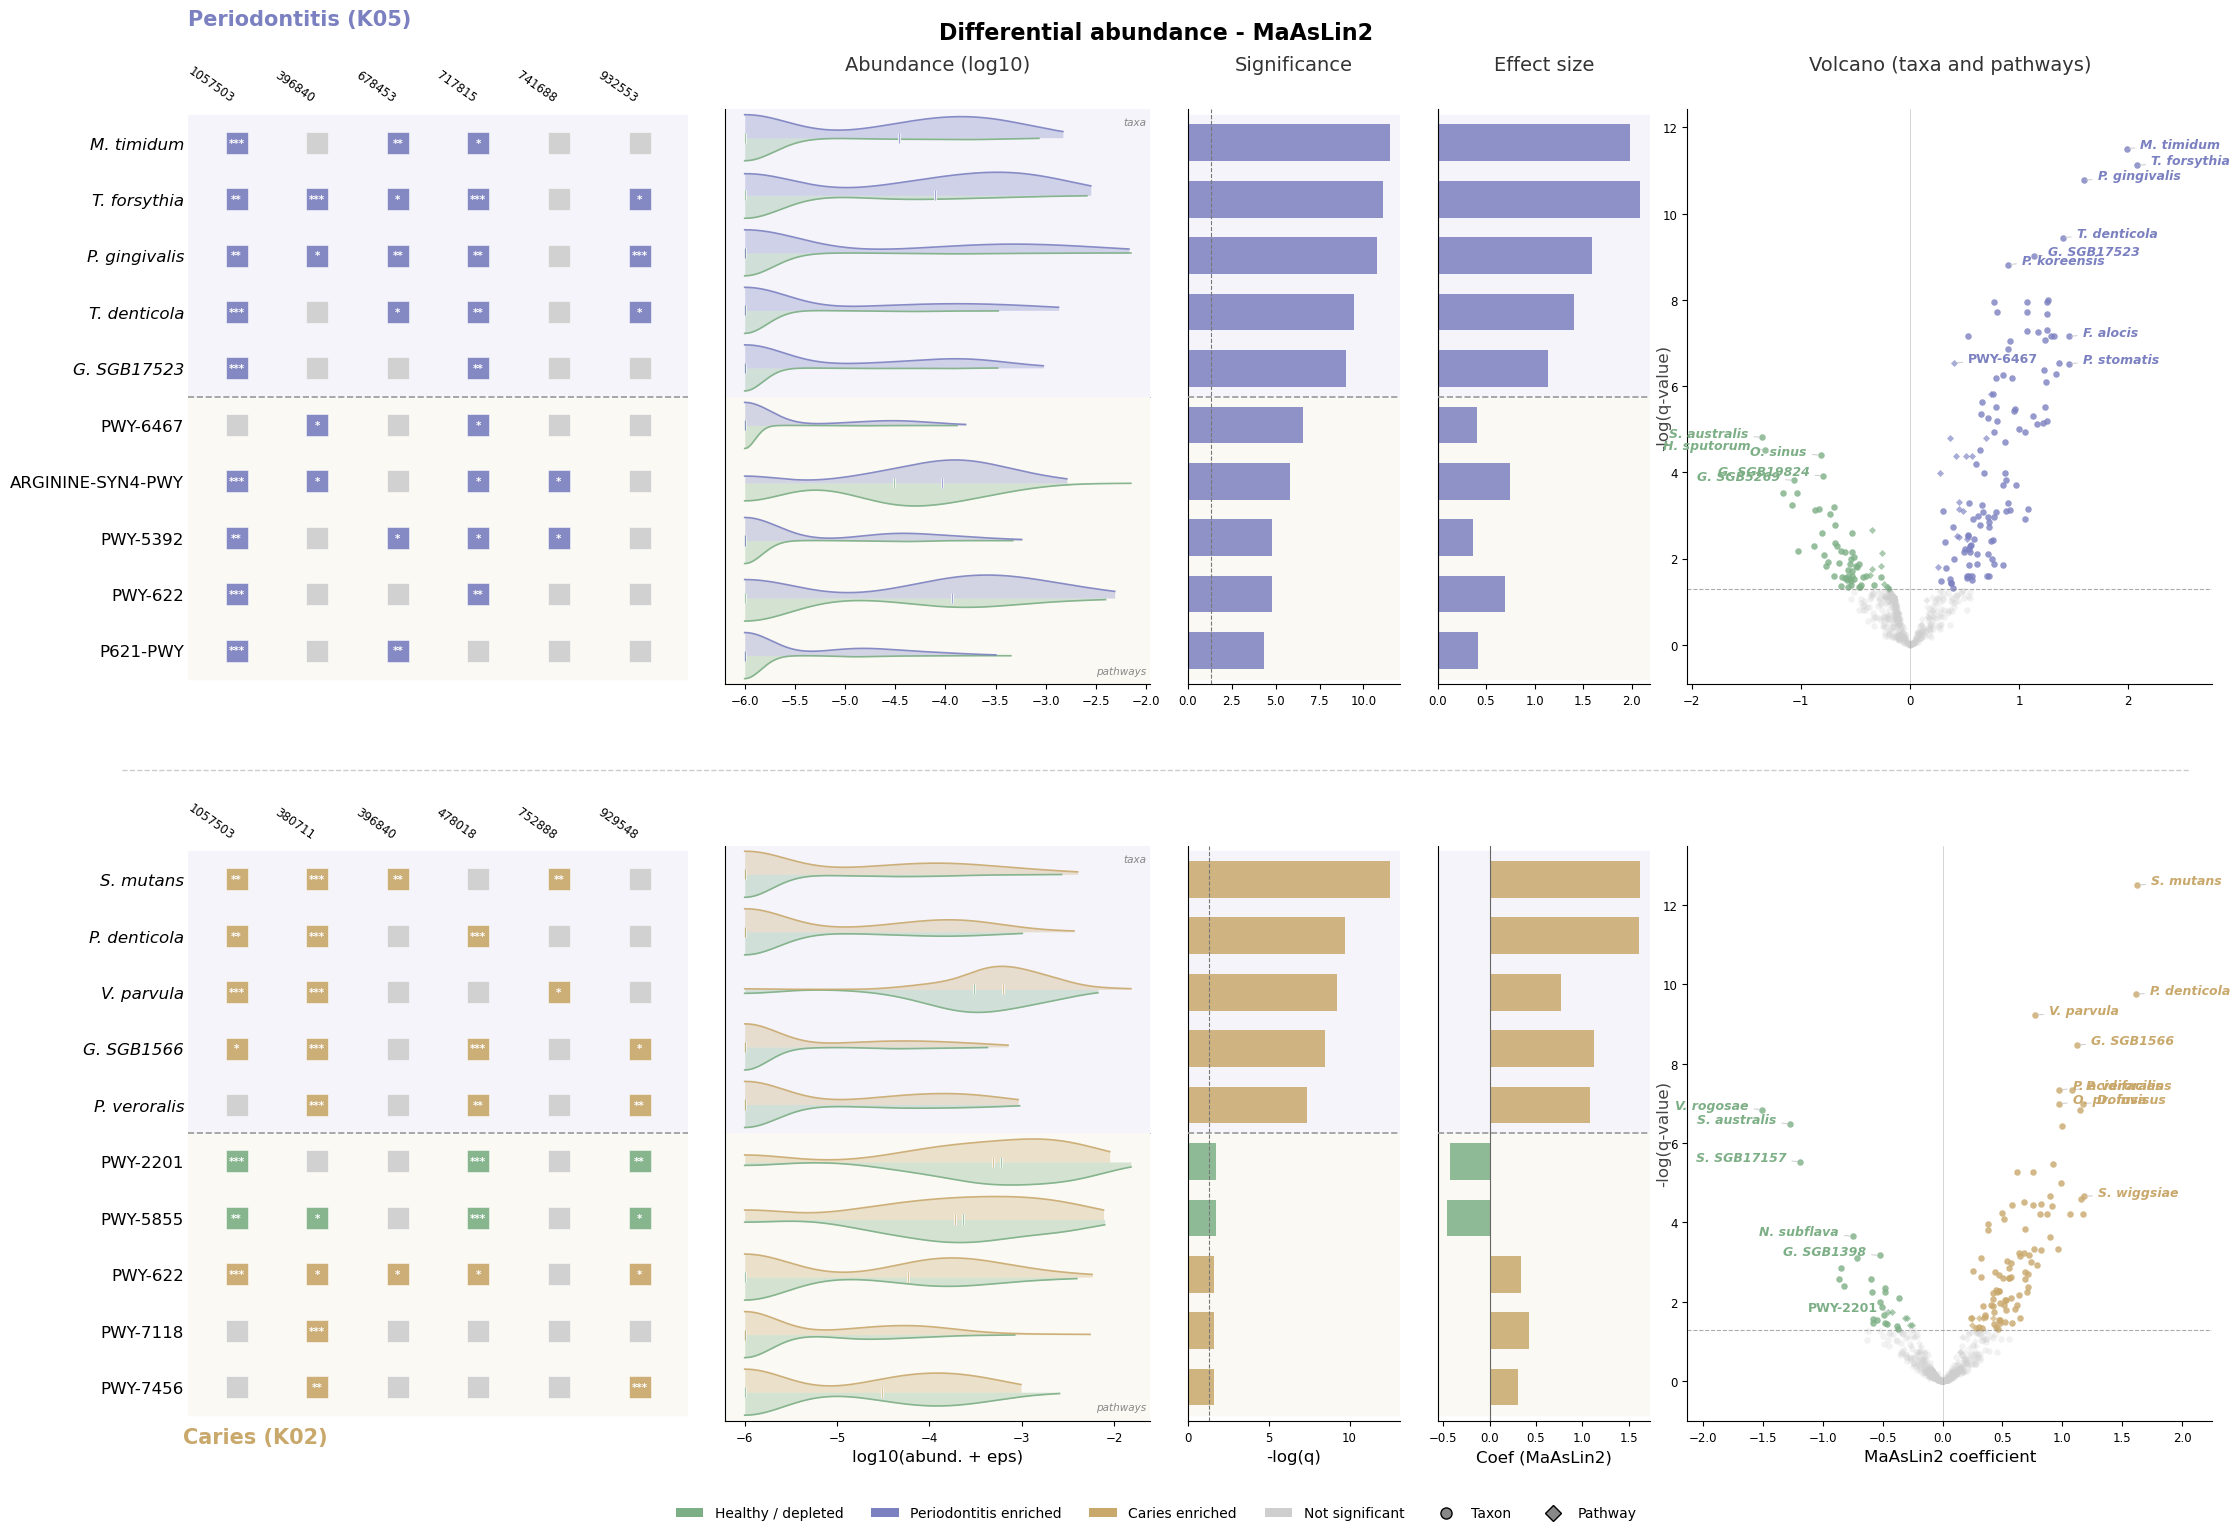

In [3]:
# Assemble and display figure
fig = plt.figure(figsize=(22, 16), facecolor="white")

outer = gridspec.GridSpec(
    2, 1, figure=fig,
    hspace=0.28, top=0.91, bottom=0.09, left=0.06, right=0.98)

draw_row(fig, outer[0], "K05", "Periodontitis (K05)",
         show_col_titles=True, show_xlabels=False)
draw_row(fig, outer[1], "K02", "Caries (K02)",
         show_col_titles=False, show_xlabels=True)

fig.add_artist(plt.Line2D(
    [0.03, 0.97], [0.497, 0.497],
    transform=fig.transFigure, color="#CCCCCC", lw=1.0, ls="--"))

fig.legend(
    handles=[
        Patch(facecolor=C_H,            label="Healthy / depleted"),
        Patch(facecolor=DIS_COL["K05"], label="Periodontitis enriched"),
        Patch(facecolor=DIS_COL["K02"], label="Caries enriched"),
        Patch(facecolor=C_NS,           label="Not significant"),
        plt.Line2D([0],[0], marker="o", color="none",
                   markerfacecolor="#888", ms=8, label="Taxon"),
        plt.Line2D([0],[0], marker="D", color="none",
                   markerfacecolor="#888", ms=8, label="Pathway"),
    ],
    loc="lower center", ncol=6,
    fontsize=FS["legend"], frameon=False, bbox_to_anchor=(0.5, 0.02))

plt.suptitle("Differential abundance - MaAsLin2",
             fontsize=FS["suptitle"], fontweight="bold", y=0.965)
plt.show()


In [4]:
# Save figure
OUT_SVG = FIGURE_DIR / "Fig_3_DA.svg"
OUT_PNG = FIGURE_DIR / "Fig_3_DA.png"

fig.savefig(OUT_SVG, bbox_inches="tight", transparent=True)
fig.savefig(OUT_PNG, dpi=DPI, bbox_inches="tight", facecolor="white")
print(f"Saved SVG -> {OUT_SVG}")
print(f"Saved PNG -> {OUT_PNG}")


Saved SVG -> results_article_configs/figures/Fig_3_DA/Fig_3_DA.svg
Saved PNG -> results_article_configs/figures/Fig_3_DA/Fig_3_DA.png


## Additional cell

Supplementary pathway annotation table for MaAsLin2 results.


In [5]:
# Supplementary pathway annotation table
def fmt_pathway_id(raw: str) -> str:
    """PWY.6307..L.tryptophan... -> PWY-6307"""
    code = str(raw).split("..")[0]
    return code.replace(".", "-")


def fmt_pathway_desc(raw: str) -> str:
    """PWY.6307..L.tryptophan.degradation.X -> L-tryptophan degradation X"""
    parts = str(raw).split("..")
    if len(parts) < 2:
        return ""
    desc = parts[1]
    desc = desc.replace(".", " ").strip()
    return " ".join(desc.split())


def metacyc_url(pathway_id: str) -> str:
    return f"https://pubchem.ncbi.nlm.nih.gov/pathway/BioCyc:META_{pathway_id}"


for dis in ["K05", "K02"]:
    df = maaslin[dis]["PATH"].copy()

    df.insert(0, "pathway_id", df["feature"].apply(fmt_pathway_id))
    df.insert(1, "pathway_description", df["feature"].apply(fmt_pathway_desc))
    df.insert(
        2,
        "direction",
        df["coef"].apply(lambda c: "enriched_in_disease" if c > 0 else "enriched_in_healthy"),
    )
    df.insert(3, "metacyc_url", df["pathway_id"].apply(metacyc_url))

    out_path = FIGURE_DIR / f"maaslin2_pathways_{dis}_annotated.tsv"
    df.to_csv(out_path, sep="\t", index=False)
    print(f"Saved {dis}: {out_path} ({len(df)} rows, {(df['qval'] < 0.05).sum()} significant)")
    display(
        df.loc[df["qval"] < 0.05, [
            "pathway_id",
            "pathway_description",
            "direction",
            "coef",
            "qval",
            "metacyc_url",
        ]]
        .sort_values("qval")
        .head(10)
    )


Saved K05: results_article_configs/figures/Fig_3_DA/maaslin2_pathways_K05_annotated.tsv (333 rows, 24 significant)


,pathway_id,pathway_description,direction,coef,qval,metacyc_url
0,PWY-6467,Kdo transfer to lipid IVA III,enriched_in_disease,0.408341,2.916298e-07,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
1,ARGININE-SYN4-PWY,L ornithine biosynthesis II,enriched_in_disease,0.744772,1.485817e-06,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
2,PWY-5392,reductive TCA cycle II,enriched_in_disease,0.367006,1.575903e-05,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
3,PWY-622,starch biosynthesis,enriched_in_disease,0.693560,1.575903e-05,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
4,P621-PWY,nylon 6 oligomer degradation,enriched_in_disease,0.419596,4.292337e-05,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
5,POLYAMINSYN3-PWY,superpathway of polyamine biosynthesis II,enriched_in_disease,0.515856,4.292337e-05,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
6,PWY-6922,L N delta,enriched_in_disease,0.566353,4.292337e-05,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
7,PWY-4702,phytate degradation I,enriched_in_disease,0.273453,1.030359e-04,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
8,PWY-6307,L tryptophan degradation X,enriched_in_disease,0.446789,4.754130e-04,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
9,PWY-6313,serotonin degradation,enriched_in_disease,0.447532,6.914950e-04,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...


Saved K02: results_article_configs/figures/Fig_3_DA/maaslin2_pathways_K02_annotated.tsv (333 rows, 11 significant)


,pathway_id,pathway_description,direction,coef,qval,metacyc_url
0,PWY-2201,folate transformations I,enriched_in_healthy,-0.421698,0.017581,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
1,PWY-5855,ubiquinol 7 biosynthesis,enriched_in_healthy,-0.457116,0.017581,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
2,PWY-622,starch biosynthesis,enriched_in_disease,0.334196,0.025087,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
3,PWY-7118,chitin deacetylation,enriched_in_disease,0.422566,0.025087,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
4,PWY-7456,beta,enriched_in_disease,0.305760,0.025087,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
5,PWY-7883,anhydromuropeptides recycling II,enriched_in_healthy,-0.315108,0.025087,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
6,P221-PWY,octane oxidation,enriched_in_disease,0.244444,0.025224,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
7,PWY0-1479,tRNA processing,enriched_in_healthy,-0.295584,0.025224,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
8,HEME-BIOSYNTHESIS-II-1,heme b biosynthesis V,enriched_in_healthy,-0.270501,0.038376,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
9,PWY-5130,2 oxobutanoate degradation I,enriched_in_disease,0.243805,0.038376,https://pubchem.ncbi.nlm.nih.gov/pathway/BioCy...
